# PBL JS02 - Pemahaman Data dan Pra Pengolahan Data

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js02-pemahaman-data-dan-pra-pengolahan-data)

Notebook ini menerapkan langkah-langkah jobsheet JS02 pada **dataset PBL: Malicious URL Detection**
(`Malicious URL Detection.csv` di root repositori). Dataset berisi 783.705 URL dengan kolom `url` dan `type`, terbagi ke 7 kelas:
`benign`, `legitimate`, `defacement`, `phishing`, `malware`, `spam`, dan `Exploit`.
URL sudah dinormalisasi oleh sumbernya (huruf kecil, tanpa `http(s)://` dan `www.`).
Fungsi muat data dan ekstraksi fitur leksikal ada di modul bersama [`pbl_url.py`](../pbl_url.py), sehingga semua notebook PBL memakai definisi fitur yang sama.

**Pemetaan langkah jobsheet → dataset PBL:**


| Jobsheet JS02 | Penerapan pada URL |
| --- | --- |
| Praktikum 1 - EDA: dimensi, tipe data, statistik, distribusi, outlier, komposisi, heatmap, scatter | EDA pada label `type` dan fitur leksikal turunan URL |
| Praktikum 2 - Data imputation | Pemeriksaan nilai hilang, string kosong, dan duplikat |
| Praktikum 3 - Slice, encoding, standardisasi | Seleksi kolom fitur, encoding label, StandardScaler |
| Praktikum 4 - Pra pengolahan data tidak terstruktur | URL sebagai teks: tokenisasi dan frekuensi token |

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pbl_url
np.random.seed(42)
print('Kernel:', sys.executable)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python


## Langkah 1 - Memuat Data

In [2]:
df = pbl_url.load_urls()
print(df.shape)
df.head()

(783705, 2)


,url,type
0,mp3raid.com/music/krizz_kaliko.html,benign
1,bopsecrets.org/rexroth/cr/1.htm,benign
2,buzzfil.net/m/show-art/ils-etaient-loin-de-s-i...,benign
3,espn.go.com/nba/player/_/id/3457/brandon-rush,benign
4,yourbittorrent.com/?q=anthony-hamilton-soulife,benign


## Langkah 2 - Inspeksi Data

### Pengecekan Dimensi dan Tipe Data

In [3]:
print('Dimensi:', df.shape)
print(df.dtypes)
print('Memori:', round(df.memory_usage(deep=True).sum() / 1e6, 1), 'MB')

Dimensi: (783705, 2)
url     str
type    str
dtype: object
Memori: 127.0 MB


Data mentah hanya memiliki satu kolom teks (`url`) dan satu label (`type`). Agar statistik deskriptif, distribusi, outlier, dan korelasi
seperti di Praktikum 1 bisa dihitung, URL diubah menjadi **28 fitur leksikal numerik** (panjang, jumlah karakter khusus, rasio digit,
alamat IP, ekstensi berkas, entropi, dan lainnya). Fitur ini mengikuti kajian deteksi URL berbahaya (Ma dkk., 2009; Mamun dkk., 2016).

In [4]:
t0 = time.perf_counter()
feats = pbl_url.lexical_features(df['url'])
print(f'Ekstraksi {feats.shape[1]} fitur untuk {len(feats):,} URL: {time.perf_counter() - t0:.1f} detik')
data = pd.concat([df, feats], axis=1)
data.head()

Ekstraksi 28 fitur untuk 783,705 URL: 19.0 detik


,url,type,url_len,host_len,path_len,query_len,n_dots,n_hyphens,n_underscores,n_slashes,...,path_depth,is_ip,has_port,is_shortener,n_suspicious_words,has_executable_ext,has_php,has_html,entropy,host_entropy
0,mp3raid.com/music/krizz_kaliko.html,benign,35,11,23,0,2,0,1,2,...,2,0,0,0,0,0,0,1,4.079143,3.277613
1,bopsecrets.org/rexroth/cr/1.htm,benign,31,14,16,0,2,0,0,3,...,3,0,0,0,0,0,0,1,3.708093,3.235926
2,buzzfil.net/m/show-art/ils-etaient-loin-de-s-i...,benign,111,11,99,0,2,16,0,3,...,3,0,0,0,0,0,0,1,4.156668,3.277613
3,espn.go.com/nba/player/_/id/3457/brandon-rush,benign,45,11,33,0,2,1,1,6,...,6,0,0,0,0,0,0,0,4.385754,3.095795
4,yourbittorrent.com/?q=anthony-hamilton-soulife,benign,46,18,0,26,1,2,0,1,...,0,0,0,0,0,0,0,0,4.205536,3.377444


### Ringkasan Nilai Statistik

In [5]:
feats.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
url_len,783705.0,56.787,63.524,1.0,29.000,44.000,72.000,25515.000
host_len,783705.0,17.305,11.500,0.0,12.000,15.000,20.000,279.000
path_len,783705.0,26.674,29.268,0.0,9.000,19.000,37.000,3211.000
query_len,783705.0,11.690,56.049,0.0,0.000,0.000,0.000,25458.000
n_dots,783705.0,2.065,1.474,0.0,1.000,2.000,2.000,42.000
n_hyphens,783705.0,1.397,2.790,0.0,0.000,0.000,1.000,88.000
n_underscores,783705.0,0.389,1.191,0.0,0.000,0.000,0.000,200.000
n_slashes,783705.0,2.123,1.738,0.0,1.000,2.000,3.000,102.000
n_question,783705.0,0.215,0.483,0.0,0.000,0.000,0.000,166.000
n_equals,783705.0,0.559,1.503,0.0,0.000,0.000,0.000,131.000


### Inspeksi Komposisi Variabel Kualitatif (label `type`)

,jumlah,persen
type,,
benign,426432,54.412
phishing,229613,29.298
defacement,95263,12.155
malware,23592,3.010
legitimate,5809,0.741
spam,2753,0.351
Exploit,243,0.031


Rasio ketidakseimbangan (kelas terbesar / terkecil): 1,755 : 1


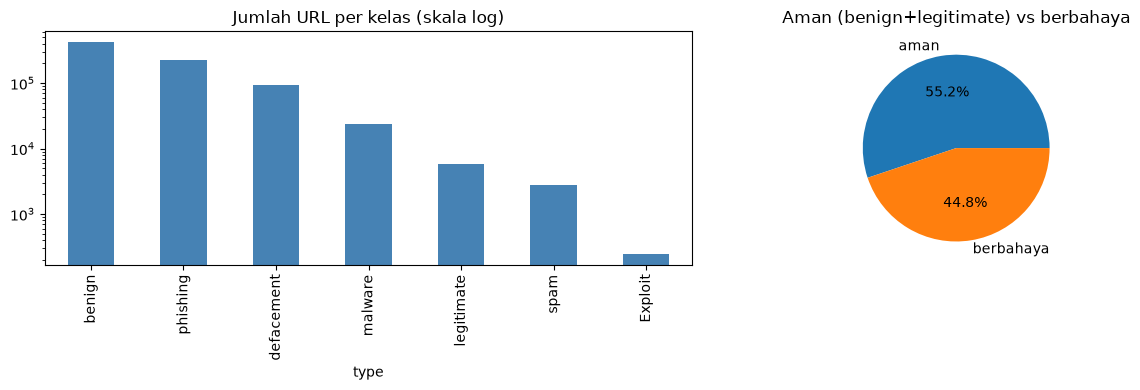

In [6]:
comp = df['type'].value_counts().to_frame('jumlah')
comp['persen'] = (100 * comp['jumlah'] / len(df)).round(3)
display(comp)
print(f"Rasio ketidakseimbangan (kelas terbesar / terkecil): {comp['jumlah'].max() / comp['jumlah'].min():,.0f} : 1")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
comp['jumlah'].plot.bar(ax=ax[0], color='steelblue'); ax[0].set_yscale('log'); ax[0].set_title('Jumlah URL per kelas (skala log)')
pd.Series(pbl_url.binary_label(df['type'])).map({0: 'aman', 1: 'berbahaya'}).value_counts().plot.pie(ax=ax[1], autopct='%.1f%%')
ax[1].set_ylabel(''); ax[1].set_title('Aman (benign+legitimate) vs berbahaya')
plt.tight_layout(); plt.show()

### Inspeksi Distribusi Data

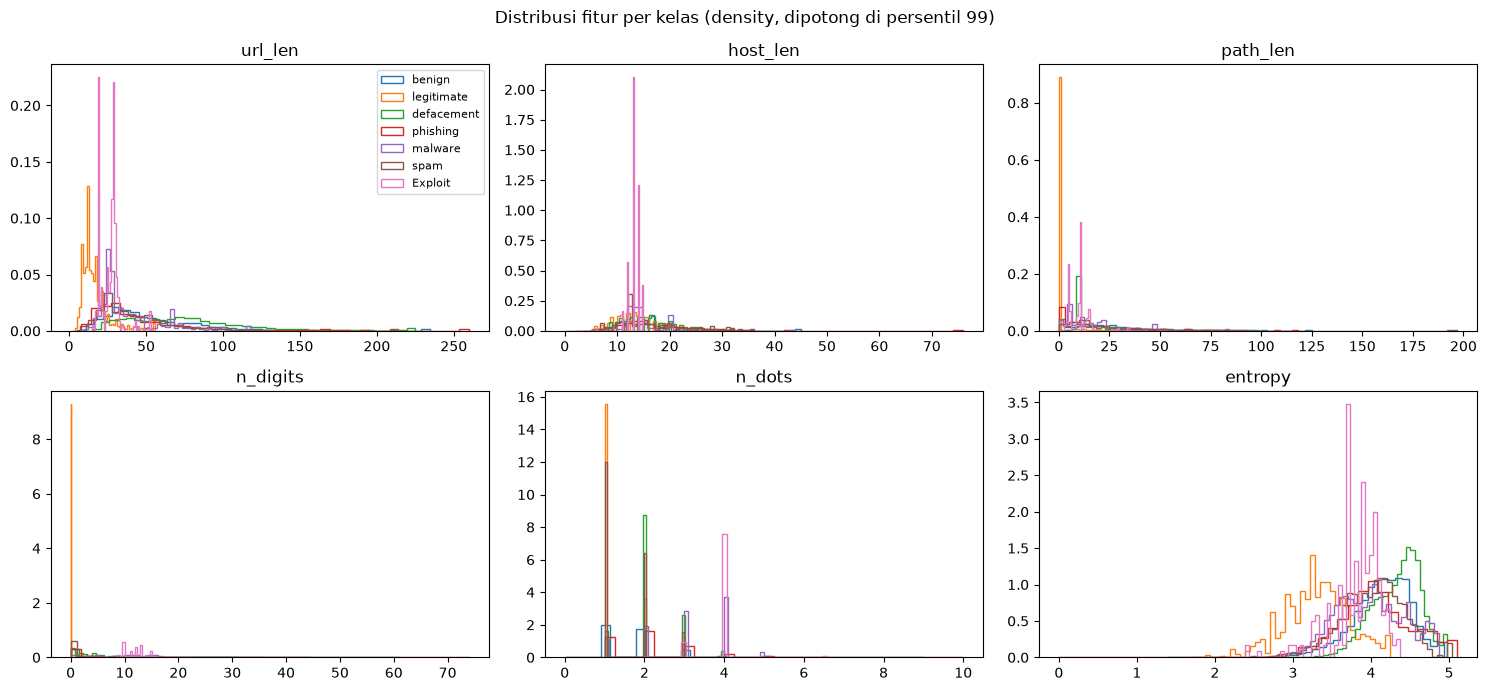

Skewness:
{'url_len': 168.07, 'host_len': 7.28, 'path_len': 8.15, 'n_digits': 48.41, 'n_dots': 4.76, 'entropy': -0.43}


In [7]:
cols = ['url_len', 'host_len', 'path_len', 'n_digits', 'n_dots', 'entropy']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, cols):
    for t in pbl_url.CLASSES:
        v = data.loc[data['type'] == t, col]
        ax.hist(v.clip(upper=v.quantile(0.99)), bins=40, histtype='step', density=True, label=t)
    ax.set_title(col)
axes[0, 0].legend(fontsize=8)
plt.suptitle('Distribusi fitur per kelas (density, dipotong di persentil 99)'); plt.tight_layout(); plt.show()
print('Skewness:'); print(feats[cols].skew().round(2).to_dict())

### Inspeksi Outlier (metode IQR / boxplot Tukey)

,tld_len,has_html,n_question,query_len,n_underscores,n_equals,n_hyphens,has_php,n_ampersand,n_suspicious_words
outlier_%,24.42,20.43,20.39,20.34,20.28,20.23,16.98,13.91,12.09,10.25


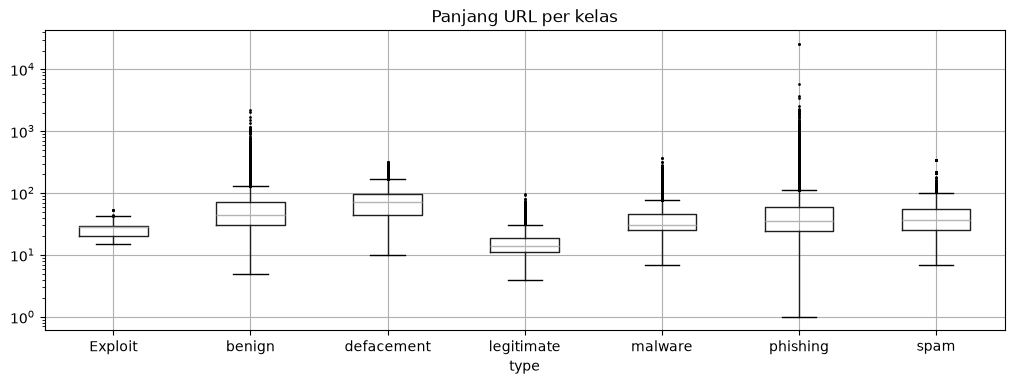

URL terpanjang: phishing 25515 karakter


In [8]:
q1, q3 = feats.quantile(0.25), feats.quantile(0.75)
iqr = q3 - q1
outlier = ((feats < q1 - 1.5 * iqr) | (feats > q3 + 1.5 * iqr))
out_tbl = pd.DataFrame({'outlier_%': (100 * outlier.mean()).round(2)}).sort_values('outlier_%', ascending=False)
display(out_tbl.head(10).T)
fig, ax = plt.subplots(figsize=(12, 4))
data.boxplot(column='url_len', by='type', ax=ax, showfliers=True, flierprops={'markersize': 1})
ax.set_yscale('log'); ax.set_title('Panjang URL per kelas'); plt.suptitle(''); plt.show()
print('URL terpanjang:', df.loc[feats['url_len'].idxmax(), 'type'], feats['url_len'].max(), 'karakter')

### Heatmap korelasi fitur

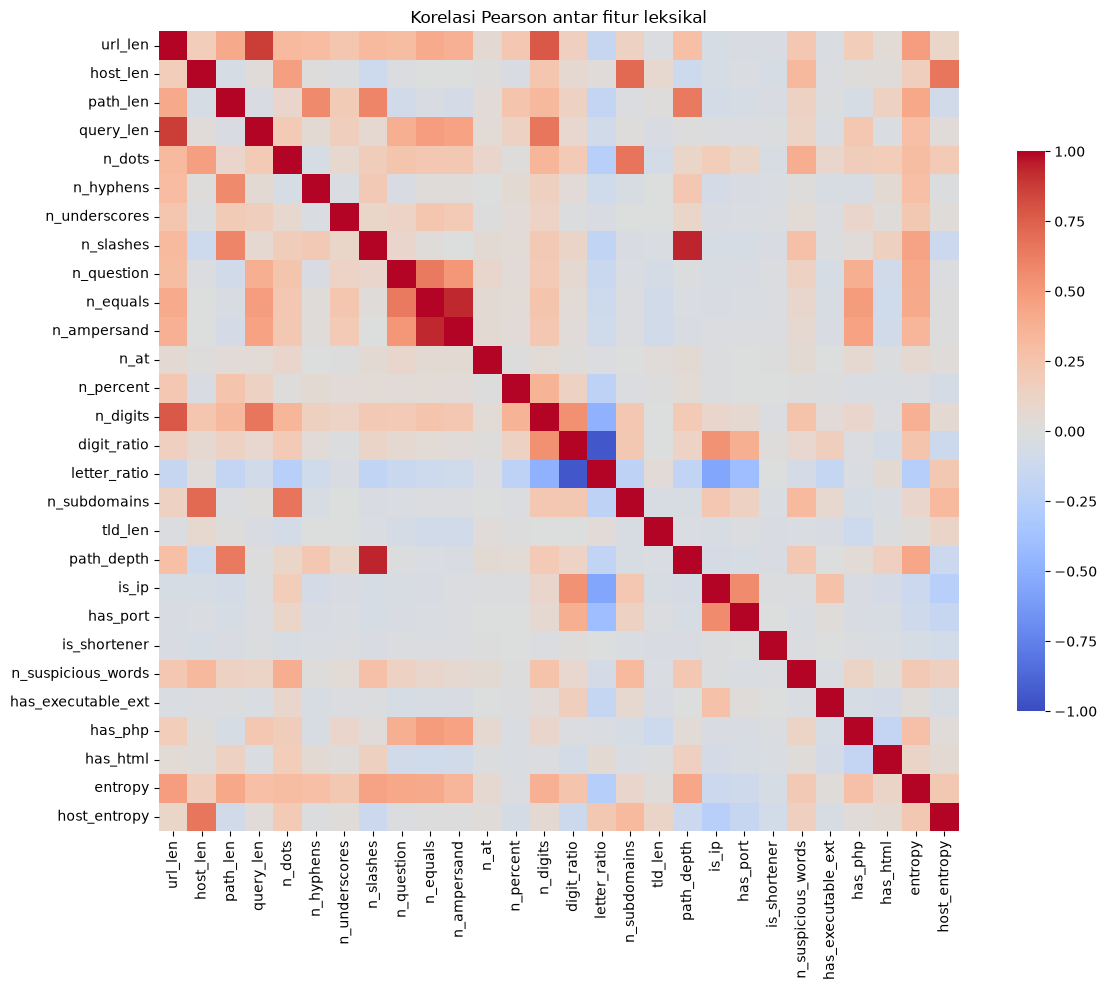

Pasangan berkorelasi tertinggi:
digit_ratio  letter_ratio   -0.946
n_slashes    path_depth      0.944
n_equals     n_ampersand     0.937
url_len      query_len       0.874
             n_digits        0.774
host_len     n_subdomains    0.712
dtype: float64


In [9]:
import seaborn as sns
corr = feats.corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'shrink': .7})
plt.title('Korelasi Pearson antar fitur leksikal'); plt.tight_layout(); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
print('Pasangan berkorelasi tertinggi:'); print(pairs.head(6).round(3))

### Scatter Plot (sampel stratified 20.000 URL)

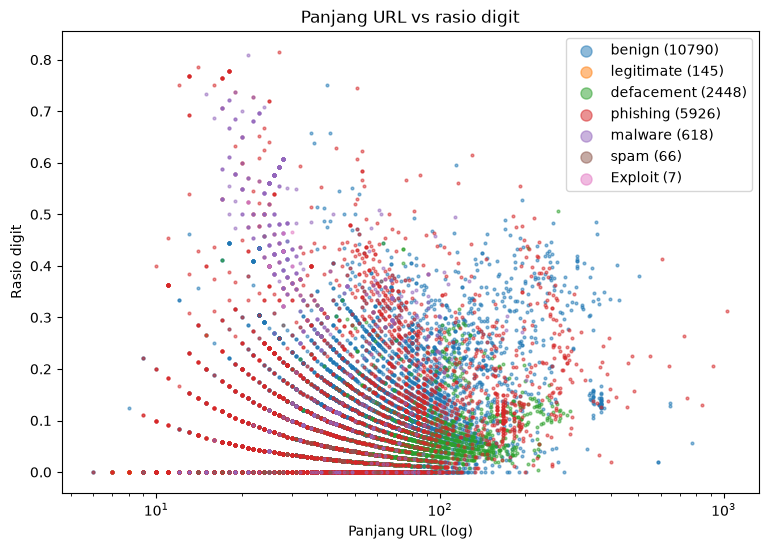

,url_len,digit_ratio,is_ip,has_executable_ext,has_php,n_suspicious_words
type,,,,,,
Exploit,26.259,0.473,0.996,0.716,0.000,0.000
benign,56.572,0.073,0.000,0.000,0.064,0.133
defacement,76.363,0.050,0.000,0.000,0.528,0.015
legitimate,16.762,0.009,0.000,0.000,0.002,0.011
malware,39.500,0.324,0.499,0.414,0.027,0.034
phishing,52.025,0.081,0.020,0.010,0.134,0.248
spam,45.359,0.042,0.000,0.000,0.033,0.024


In [10]:
s = data.sample(20000, random_state=42)
plt.figure(figsize=(9, 6))
for t in pbl_url.CLASSES:
    part = s[s['type'] == t]
    plt.scatter(part['url_len'], part['digit_ratio'], s=4, alpha=.5, label=f'{t} ({len(part)})')
plt.xscale('log'); plt.xlabel('Panjang URL (log)'); plt.ylabel('Rasio digit'); plt.legend(markerscale=4)
plt.title('Panjang URL vs rasio digit'); plt.show()
data.groupby('type')[['url_len', 'digit_ratio', 'is_ip', 'has_executable_ext', 'has_php', 'n_suspicious_words']].mean().round(3)

## Praktikum 2 - Pemeriksaan Missing Value dan Kebutuhan Imputasi

In [11]:
print('Missing per kolom:'); print(df.isna().sum())
print('URL string kosong:', (df['url'].str.strip() == '').sum())
print('Baris duplikat persis:', df.duplicated().sum())
norm = df['url'].str.rstrip('/')
dup = norm.duplicated(keep=False)
print('Duplikat setelah menghapus "/" di akhir:', norm.duplicated().sum(),
      '| grup dengan label berbeda:', (df[dup].assign(n=norm[dup]).groupby('n')['type'].nunique() > 1).sum())

Missing per kolom:
url     0
type    0
dtype: int64


URL string kosong: 0
Baris duplikat persis: 0


Duplikat setelah menghapus "/" di akhir: 0 | grup dengan label berbeda: 0


Tidak ada nilai hilang, string kosong, maupun duplikat yang labelnya bertentangan, sehingga **imputasi tidak diperlukan**.
Imputasi rata-rata/median dari Praktikum 2 hanya relevan untuk fitur numerik yang hilang. Pada fitur leksikal, nilainya selalu dapat dihitung dari URL.
Setelah `/` di akhir dihapus pun tidak ada URL yang duplikat.

## Praktikum 3 - Slice Data, Encoding, dan Standardisasi

In [12]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
# Slice: pilih fitur numerik dan label
X = data[pbl_url.FEATURE_NAMES]
y_text = data['type']

# Encoding label multikelas dan biner
le = LabelEncoder()
y = le.fit_transform(y_text)
print(dict(zip(le.classes_, le.transform(le.classes_))))
y_bin = pbl_url.binary_label(y_text)
print('Label biner berbahaya=1:', np.bincount(y_bin))

# Encoding fitur kategorikal: TLD (one-hot untuk 15 TLD terbanyak, sisanya 'other')
tld = df['url'].str.split('/').str[0].str.split(':').str[0].str.rsplit('.', n=1).str[-1]
top = tld.value_counts().index[:15]
tld_onehot = pd.get_dummies(tld.where(tld.isin(top), 'other'), prefix='tld', dtype=int)
print('One-hot TLD:', tld_onehot.shape)
display(pd.crosstab(tld.where(tld.isin(top[:8]), 'other'), y_text, normalize='columns').round(3))

{'Exploit': np.int64(0), 'benign': np.int64(1), 'defacement': np.int64(2), 'legitimate': np.int64(3), 'malware': np.int64(4), 'phishing': np.int64(5), 'spam': np.int64(6)}
Label biner berbahaya=1: [432241 351464]


One-hot TLD: (783705, 16)


type,Exploit,benign,defacement,legitimate,malware,phishing,spam
url,,,,,,,
br,0.0,0.005,0.053,0.004,0.002,0.019,0.000
ca,0.0,0.023,0.004,0.007,0.001,0.006,0.002
com,0.0,0.723,0.306,0.626,0.253,0.506,0.790
de,0.0,0.003,0.113,0.013,0.002,0.010,0.000
edu,0.0,0.016,0.000,0.024,0.000,0.014,0.005
net,0.0,0.044,0.036,0.044,0.009,0.044,0.004
org,0.0,0.088,0.037,0.060,0.010,0.057,0.100
other,1.0,0.084,0.418,0.183,0.719,0.328,0.094
uk,0.0,0.013,0.034,0.039,0.004,0.018,0.005


In [13]:
# Standardisasi fitur numerik
scaler = StandardScaler()
X_std = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
check = pd.DataFrame({'mean_sebelum': X.mean(), 'std_sebelum': X.std(), 'mean_sesudah': X_std.mean(), 'std_sesudah': X_std.std()})
check.round(3).head(10)

,mean_sebelum,std_sebelum,mean_sesudah,std_sesudah
url_len,56.787,63.524,-0.0,1.0
host_len,17.305,11.500,0.0,1.0
path_len,26.674,29.268,0.0,1.0
query_len,11.690,56.049,-0.0,1.0
n_dots,2.065,1.474,-0.0,1.0
n_hyphens,1.397,2.790,-0.0,1.0
n_underscores,0.389,1.191,-0.0,1.0
n_slashes,2.123,1.738,-0.0,1.0
n_question,0.215,0.483,0.0,1.0
n_equals,0.559,1.503,0.0,1.0


## Praktikum 4 - Pra Pengolahan Data Tidak Terstruktur (URL sebagai teks)

In [14]:
import re
from collections import Counter
tokenize = lambda u: [t for t in re.split(r'[/\.\?=&\-_:%~+]', u) if t]
print('Contoh:', df['url'].iloc[2]); print('Token :', tokenize(df['url'].iloc[2]))
top_tokens = {}
for t in pbl_url.CLASSES:
    cnt = Counter(tok for u in df.loc[df['type'] == t, 'url'].sample(min(20000, (df['type'] == t).sum()), random_state=1) for tok in tokenize(u))
    top_tokens[t] = [w for w, _ in cnt.most_common(10)]
pd.DataFrame(top_tokens)

Contoh: buzzfil.net/m/show-art/ils-etaient-loin-de-s-imaginer-que-le-hibou-allait-faire-ceci-quand-ils-filmaient-2.html
Token : ['buzzfil', 'net', 'm', 'show', 'art', 'ils', 'etaient', 'loin', 'de', 's', 'imaginer', 'que', 'le', 'hibou', 'allait', 'faire', 'ceci', 'quand', 'ils', 'filmaient', '2', 'html']


,benign,legitimate,defacement,phishing,malware,spam,Exploit
0,com,com,com,com,com,com,bin
1,html,org,index,html,exe,muckrack,280
2,org,co,php,php,m,org,payload
3,htm,net,option,ipfs,mozi,substack,78
4,net,uk,id,index,uploads,the,sh
5,en,html,itemid,net,jp,2020,140
6,php,edu,view,org,mixh,unsubscribe,153
7,d8,in,html,login,mitsui,manage,96
8,index,google,content,wp,jyuku,list,bins
9,wiki,htm,article,htm,bins,numlock,185


## Analisis

**1. Data sangat tidak seimbang.** `benign` 54,41%, `phishing` 29,30%, `defacement` 12,16%, `malware` 3,01%, `legitimate` 0,74%, `spam` 0,35%, dan `Exploit` hanya 0,031% (243 URL). Rasio kelas terbesar dan terkecil mencapai 1.755 : 1. Akibatnya, **akurasi bukan metrik yang tepat**: model yang selalu menebak `benign` sudah mencapai 54% tanpa mendeteksi satu pun ancaman. Notebook PBL berikutnya memakai **macro-F1** dan split *stratified* (He & Garcia, 2009). Secara biner, kelompok aman dan berbahaya cukup seimbang (55% : 45%).

**2. Pola leksikal per kelas sangat berbeda** dan sejalan dengan literatur deteksi URL (Ma dkk., 2009; Mamun dkk., 2016):

| Kelas | Rata-rata panjang | Rasio digit | Host berupa IP | Ekstensi executable | `.php` | Rata-rata `=` |
| --- | --- | --- | --- | --- | --- | --- |
| Exploit | 26 | 0,47 | 99,6% | 71,6% | 0% | 0,00 |
| malware | 40 | 0,32 | 49,9% | 41,4% | 2,7% | 0,17 |
| defacement | 76 | 0,05 | 0% | 0% | 52,8% | 2,31 |
| phishing | 52 | 0,08 | 2,0% | 1,0% | 13,4% | 0,33 |
| benign | 57 | 0,07 | 0% | 0% | 6,4% | 0,32 |
| legitimate | 17 | 0,01 | 0% | 0% | 0,2% | 0,01 |

* `Exploit` dan `malware` didominasi URL ke **alamat IP langsung** dengan berkas biner untuk arsitektur IoT (`.arm`, `.mips`, `.sh`, token `bins`, `mozi`), yaitu pola penyebaran botnet seperti Mirai/Mozi.
* `defacement` adalah URL CMS Joomla yang panjang (`index.php?option=com_content&view=article&id=...`), sehingga memiliki parameter `=` terbanyak.
* `phishing` paling sering memuat kata mencurigakan (0,248 per URL; token `login`, `wp`, `ipfs`), sesuai temuan Garera dkk. (2007).
* `legitimate` hampir selalu berupa **domain saja** (rata-rata 17 karakter). Pola ini berbeda dengan `benign` yang berupa halaman lengkap, sehingga kedua kelas "aman" ini mungkin berasal dari sumber data berbeda. Model dapat belajar membedakan **sumber data**, bukan tingkat bahaya. Arp dkk. (2022) menyebut gejala ini *spurious correlation* dalam ML keamanan.

**3. Distribusi dan outlier.** Fitur hitungan sangat menceng ke kanan: skewness `url_len` 168 dan `n_digits` 48. URL terpanjang adalah `phishing` dengan 25.515 karakter, sementara persentil 99 hanya 240. Metode IQR menandai 20-24% data sebagai outlier pada fitur seperti `tld_len`, `n_question`, dan `query_len`. Namun "outlier" ini justru merupakan **sinyal kelas** (misalnya query panjang pada `defacement`), bukan kesalahan data, sehingga tidak dihapus. Untuk model berbasis jarak, transformasi `log1p` lebih tepat daripada membuang data.

**4. Korelasi.** Beberapa fitur hampir redundan, misalnya `digit_ratio`-`letter_ratio` (-0,95), `n_slashes`-`path_depth` (0,94), dan `n_equals`-`n_ampersand` (0,94). Fitur-fitur ini kandidat untuk dibuang pada seleksi fitur (PBL JS03).

**5. Kualitas data.** Tidak ada missing value, string kosong, maupun duplikat, sehingga imputasi tidak diperlukan. Standardisasi menghasilkan rata-rata 0 dan simpangan baku 1 pada semua fitur. One-hot TLD menunjukkan bahwa TLD di luar 15 terbanyak mencakup 100% `Exploit` (semuanya IP) dan 72% `malware`.

## Rujukan

1. Ma, J., Saul, L. K., Savage, S., & Voelker, G. M. (2009). Beyond blacklists: Learning to detect malicious web sites from suspicious URLs. *Proceedings of the 15th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 1245-1254. https://doi.org/10.1145/1557019.1557153
2. Mamun, M. S. I., Rathore, M. A., Lashkari, A. H., Stakhanova, N., & Ghorbani, A. A. (2016). Detecting malicious URLs using lexical analysis. *Network and System Security (NSS 2016)*, LNCS 9955, 467-482. https://doi.org/10.1007/978-3-319-46298-1_30
3. Sahoo, D., Liu, C., & Hoi, S. C. H. (2017). Malicious URL detection using machine learning: A survey. *arXiv:1701.07179*. https://arxiv.org/abs/1701.07179
4. Garera, S., Provos, N., Chew, M., & Rubin, A. D. (2007). A framework for detection and measurement of phishing attacks. *Proceedings of the 2007 ACM Workshop on Recurring Malcode (WORM)*, 1-8. https://doi.org/10.1145/1314389.1314391
5. He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering*, 21(9), 1263-1284. https://doi.org/10.1109/TKDE.2008.239
6. Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.